# F1nalyze — 4-class classification of F1 race results
*(Version 3: row recovery without losing predictions + DNF risk features)*

**Target A:** `positionOrder` (finishing position) → 4 classes: win (1) / podium (2–3) / points (4–10) / rest (>10)
**Data:** F1nalyze Datathon | Train 1950–2013 / Val 2013–2018 / Test 2018–2023

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (f1_score, balanced_accuracy_score,
                              classification_report, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_sample_weight
try:
    from scipy.optimize import minimize as scipy_minimize
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False
try:
    from lightgbm import LGBMClassifier
    BOOST_TYPE = 'LGB'
except ImportError:
    from xgboost import XGBClassifier
    BOOST_TYPE = 'XGB'

SEED = 42
np.random.seed(SEED)
DATA_DIR = Path('data')
NA_VALS = [r'\N']
CLASSES = ['win', 'podium', 'points', 'rest']
plt.rcParams['figure.dpi'] = 110
sns.set_theme(style='whitegrid', palette='tab10')
print(f'Gradient boosting: {BOOST_TYPE}')
print('Libraries loaded.')

Gradient boosting: LGB
Libraries loaded.


## 1. Loading the data and REPAIRING it (Step 0)

The raw files are a **broken Cartesian product** (train: ~2.8M rows, **22,089** distinct `resultId` values in the file).
Every result (driver × race) has **many championship-standings snapshots** from different rounds glued onto it.

**What is `racerId`?** It is the **race identifier** of a given result (while `raceId_y` is the race the attached
standings snapshot comes from). `racerId` has **no missing values** and is **not** a driver identifier — who is who
is given by `driverId`, and the submission row is identified by `result_driver_standing`.

**Repair = filtering ROWS, not dropping a column.** We keep the row where `raceId_y == racerId` (the snapshot for
*this* race) → exactly 1 row per `resultId`. No column (`racerId`, `driverId`, `result_driver_standing`)
disappears, so **we always know whom we are predicting for**.

**Recovery instead of loss.** For ~2% of results (mostly the **1990s/2000s**, *not* the oldest eras) there is no snapshot
for exactly that race. Instead of dropping them, we substitute the **nearest earlier** snapshot and blank out the
*post*-race standings columns (`points_y`, `wins`, `position`, `positionText_y`), which are then imputed. This avoids
leakage (the snapshot predates the race). In val and test **every** result is recovered, so no prediction is lost;
in train a small number of results has no earlier snapshot at all and is dropped (the count is printed below).

In [2]:
# Post-race standings columns — for recovered rows they come from another race, so we blank them
POST_RACE_STANDINGS = ['points_y', 'wins', 'position', 'positionText_y']

exact_parts, fb_parts = [], []
all_ids = set()
for chunk in pd.read_csv(
    DATA_DIR / 'train.csv', dtype=str,
    na_values=NA_VALS, keep_default_na=False, chunksize=200_000
):
    chunk = chunk.assign(
        _ry=pd.to_numeric(chunk['raceId_y'], errors='coerce'),
        _rc=pd.to_numeric(chunk['racerId'],  errors='coerce'),
    )
    all_ids.update(chunk['resultId'].unique())
    # 1) exact snapshot for this race
    exact_parts.append(chunk[chunk['_ry'] == chunk['_rc']])
    # 2) fallback candidates: snapshot from the NEAREST EARLIER race (max raceId_y < racerId)
    cand = chunk[chunk['_ry'] < chunk['_rc']]
    if len(cand):
        fb_parts.append(cand.loc[cand.groupby('resultId')['_ry'].idxmax()])

train_exact = pd.concat(exact_parts, ignore_index=True)
train_exact['_recovered'] = 0
missing_ids = all_ids - set(train_exact['resultId'])

fb_all = pd.concat(fb_parts, ignore_index=True) if fb_parts else train_exact.iloc[:0].copy()
fb_all = fb_all[fb_all['resultId'].isin(missing_ids)]
fb_all = fb_all.sort_values('_ry').groupby('resultId', as_index=False).tail(1).copy()
fb_all['_recovered'] = 1
fb_all.loc[:, POST_RACE_STANDINGS] = np.nan  # post-race standings from another round -> imputation

train_raw = pd.concat([train_exact, fb_all], ignore_index=True).drop(columns=['_ry', '_rc'])
n_uniq = train_raw['resultId'].nunique()
not_recovered = len(missing_ids) - len(fb_all)

assert len(train_raw) == n_uniq, 'ERROR: not 1 row per resultId!'
print(f'train: {len(train_raw):,} rows | {n_uniq:,} unique resultId (out of {len(all_ids):,} in the file)')
print(f'  exact snapshot: {(train_raw["_recovered"]==0).sum():,}'
      f' | recovered: {(train_raw["_recovered"]==1).sum():,}'
      f' | not recovered (dropped): {not_recovered}')
print('Check OK (1 row = 1 resultId)')

train: 21,966 rows | 21,966 unique resultId (out of 22,089 in the file)
  exact snapshot: 21,643 | recovered: 323 | not recovered (dropped): 123
Check OK (1 row = 1 resultId)


In [3]:
def load_and_fix(path):
    df = pd.read_csv(path, dtype=str, na_values=NA_VALS, keep_default_na=False)
    df = df.assign(
        _ry=pd.to_numeric(df['raceId_y'], errors='coerce'),
        _rc=pd.to_numeric(df['racerId'],  errors='coerce'),
    )
    exact = df[df['_ry'] == df['_rc']].copy()
    exact['_recovered'] = 0
    missing = set(df['resultId'].unique()) - set(exact['resultId'])
    cand = df[df['resultId'].isin(missing) & (df['_ry'] < df['_rc'])].copy()
    if len(cand):
        cand = cand.sort_values('_ry').groupby('resultId', as_index=False).tail(1).copy()
        cand['_recovered'] = 1
        cand.loc[:, POST_RACE_STANDINGS] = np.nan
    out = pd.concat([exact, cand], ignore_index=True).drop(columns=['_ry', '_rc'])
    n = out['resultId'].nunique()
    assert len(out) == n, f'ERROR: {path}'
    return out, len(df['resultId'].unique()) - n

val_raw,  miss_val  = load_and_fix(DATA_DIR / 'validation.csv')
test_raw, miss_test = load_and_fix(DATA_DIR / 'test.csv')
print(f'val:  {len(val_raw):,} (recovered {int((val_raw["_recovered"]==1).sum())}, not recovered {miss_val})')
print(f'test: {len(test_raw):,} (recovered {int((test_raw["_recovered"]==1).sum())}, not recovered {miss_test})')

val:  1,836 (recovered 1, not recovered 0)
test: 2,133 (recovered 3, not recovered 0)


In [4]:
COLS_NUM = [
    'resultId','racerId','driverId','constructorId','grid',
    'positionOrder','points','laps','timetaken_in_millisec',
    'fastestLap','rank','statusId','year','round','circuitId',
    'driverStandingsId','raceId_y','points_y','wins'
]
def convert_types(df):
    df = df.copy()
    for col in COLS_NUM:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    if 'position' in df.columns:
        df['position'] = pd.to_numeric(df['position'], errors='coerce')
    df['dob']  = pd.to_datetime(df.get('dob'),  errors='coerce')
    df['date'] = pd.to_datetime(df.get('date'), errors='coerce')
    return df

train = convert_types(train_raw)
val   = convert_types(val_raw)
test  = convert_types(test_raw)
print(f'train: {train.shape} | val: {val.shape} | test: {test.shape}')

train: (21966, 56) | val: (1836, 56) | test: (2133, 56)


## 2. EDA — exploratory data analysis (after the repair)

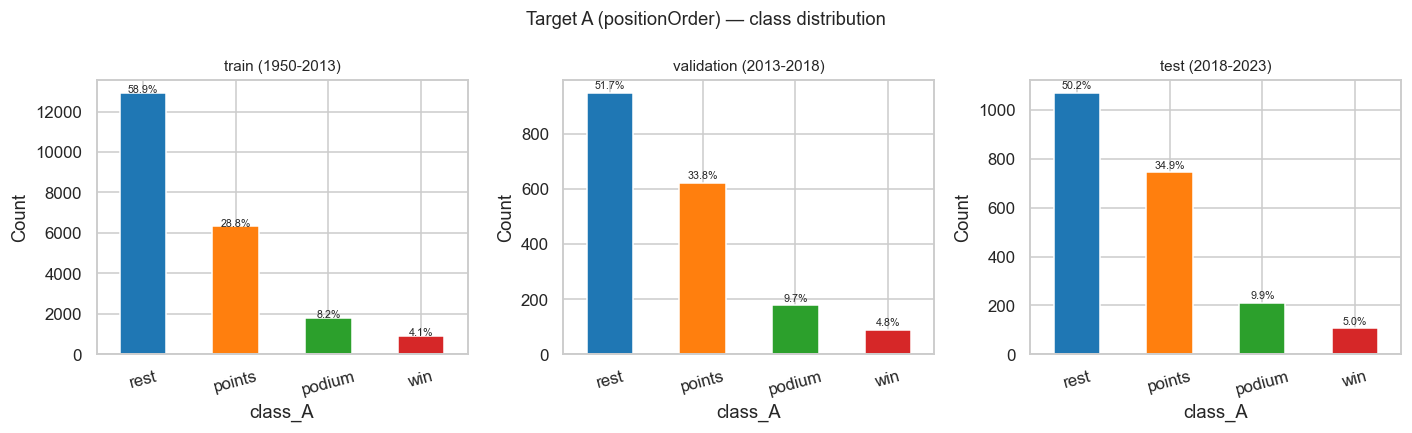

Train: {'rest': 12933, 'points': 6321, 'podium': 1812, 'win': 900}


In [5]:
def map_classes(s):
    s = pd.to_numeric(s, errors='coerce')
    return pd.cut(s, bins=[0, 1, 3, 10, np.inf],
                  labels=['win', 'podium', 'points', 'rest'], right=True)

train['class_A'] = map_classes(train['positionOrder'])
val['class_A']   = map_classes(val['positionOrder'])
test['class_A']  = map_classes(test['positionOrder'])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, df, name in [(axes[0], train, 'train (1950-2013)'),
                     (axes[1], val,   'validation (2013-2018)'),
                     (axes[2], test,  'test (2018-2023)')]:
    cnt = df['class_A'].value_counts()
    cnt.plot(kind='bar', ax=ax, color=sns.color_palette('tab10', 4))
    ax.set_title(name, fontsize=10)
    ax.tick_params(axis='x', rotation=15)
    ax.set_ylabel('Count')
    for p in ax.patches:
        pct = p.get_height() / len(df) * 100
        if pct > 0:
            ax.annotate(f'{pct:.1f}%',
                        (p.get_x() + p.get_width()/2, p.get_height() + 15),
                        ha='center', fontsize=7)
plt.suptitle('Target A (positionOrder) — class distribution', fontsize=12)
plt.tight_layout()
plt.show()
print('Train:', {k: int(v) for k, v in train['class_A'].value_counts().items()})

**A note on class consistency and on removing Target B:**
- The classes win / podium / points are **race** concepts — they fit `positionOrder` (Target A).
- In train (1950–2013) the "points (4–10)" class means a **band of finishing positions**, not literal points (before 2003 only the top 5/6/8 scored). The val and test sets (2013–2023) are in the top-10 era, so the evaluation is consistent.
- **Target B (`position`) removed.** Podium/points make no sense for the championship standings. A trivial rule dominated it (macro-F1 ≈ 0.86) because of the autocorrelation of the standings table.

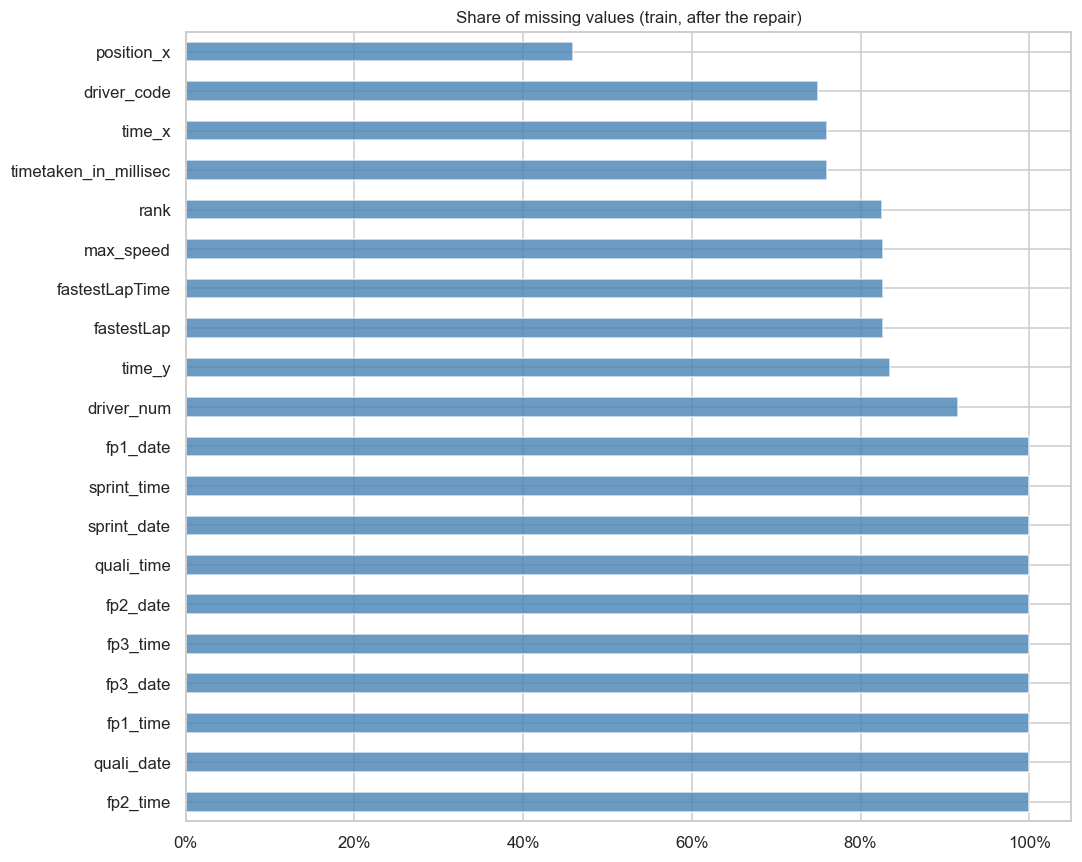

fp2_time                 1.000000
quali_date               1.000000
fp1_time                 1.000000
fp3_date                 1.000000
fp3_time                 1.000000
fp2_date                 1.000000
quali_time               1.000000
sprint_date              1.000000
sprint_time              1.000000
fp1_date                 1.000000
driver_num               0.915415
time_y                   0.835018
fastestLap               0.826869
fastestLapTime           0.826869
max_speed                0.826869
rank                     0.825002
timetaken_in_millisec    0.760311
time_x                   0.760266
driver_code              0.749112
position_x               0.458982


In [6]:
missing_rate = train.isnull().mean().sort_values(ascending=False)
missing_nz = missing_rate[missing_rate > 0].head(20)
fig, ax = plt.subplots(figsize=(10, max(3, len(missing_nz) * 0.4)))
missing_nz.plot(kind='barh', ax=ax, color='steelblue', alpha=0.8)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title('Share of missing values (train, after the repair)', fontsize=11)
plt.tight_layout()
plt.show()
print(missing_nz.to_string())

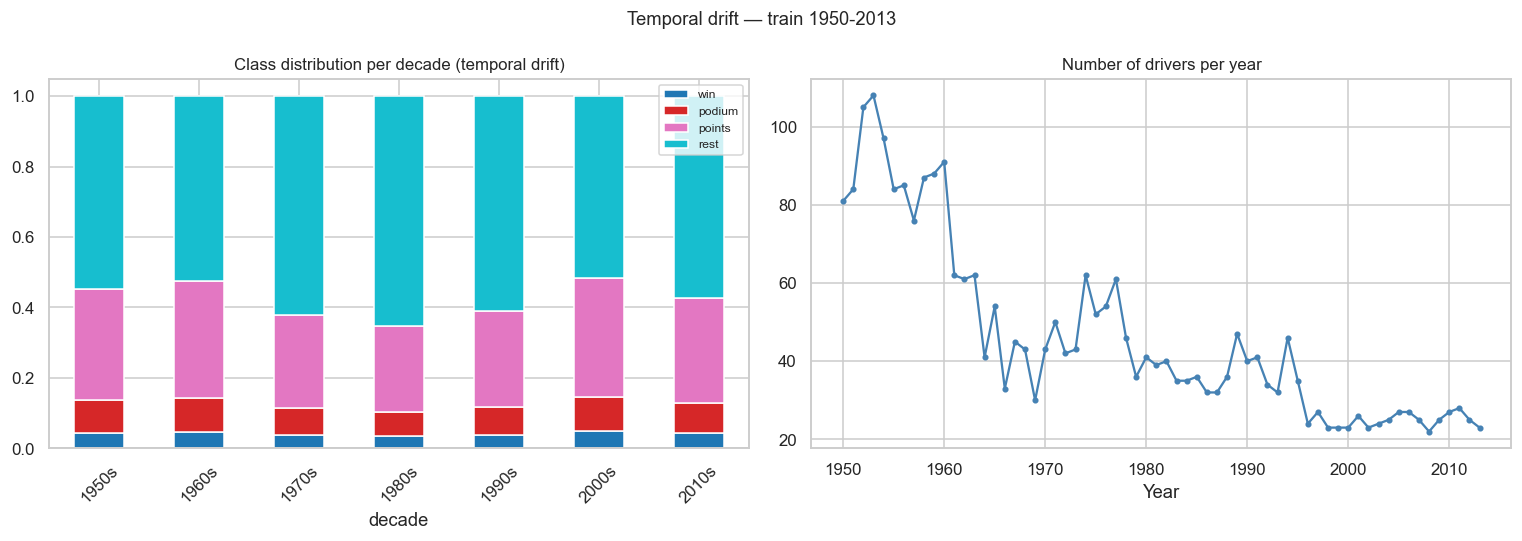

In [7]:
df_drift = train.copy()
df_drift['decade'] = (df_drift['year'] // 10 * 10).astype(int).astype(str) + 's'
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cross = df_drift.groupby(['decade', 'class_A']).size().unstack(fill_value=0)
cross_pct = cross.div(cross.sum(axis=1), axis=0)
cross_pct[['win', 'podium', 'points', 'rest']].plot(
    kind='bar', stacked=True, ax=axes[0], colormap='tab10')
axes[0].set_title('Class distribution per decade (temporal drift)', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(loc='upper right', fontsize=8)

drv = train.groupby('year')['driverId'].nunique()
axes[1].plot(drv.index, drv.values, 'o-', markersize=3, color='steelblue')
axes[1].set_title('Number of drivers per year', fontsize=11)
axes[1].set_xlabel('Year')
plt.suptitle('Temporal drift — train 1950-2013', fontsize=12)
plt.tight_layout()
plt.show()

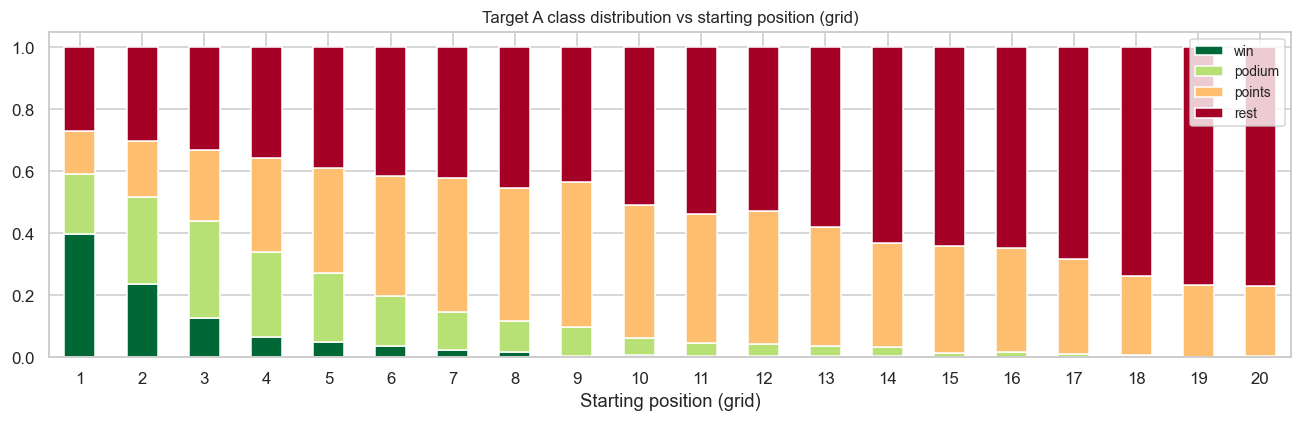

Takeaway: grid is the strongest predictor.


In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
gk = (train[train['grid'].between(1, 20)]
      .groupby('grid')['class_A']
      .value_counts(normalize=True)
      .unstack(fill_value=0))
gk[['win', 'podium', 'points', 'rest']].plot(
    kind='bar', stacked=True, ax=ax, colormap='RdYlGn_r')
ax.set_title('Target A class distribution vs starting position (grid)', fontsize=11)
ax.set_xlabel('Starting position (grid)')
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()
print('Takeaway: grid is the strongest predictor.')

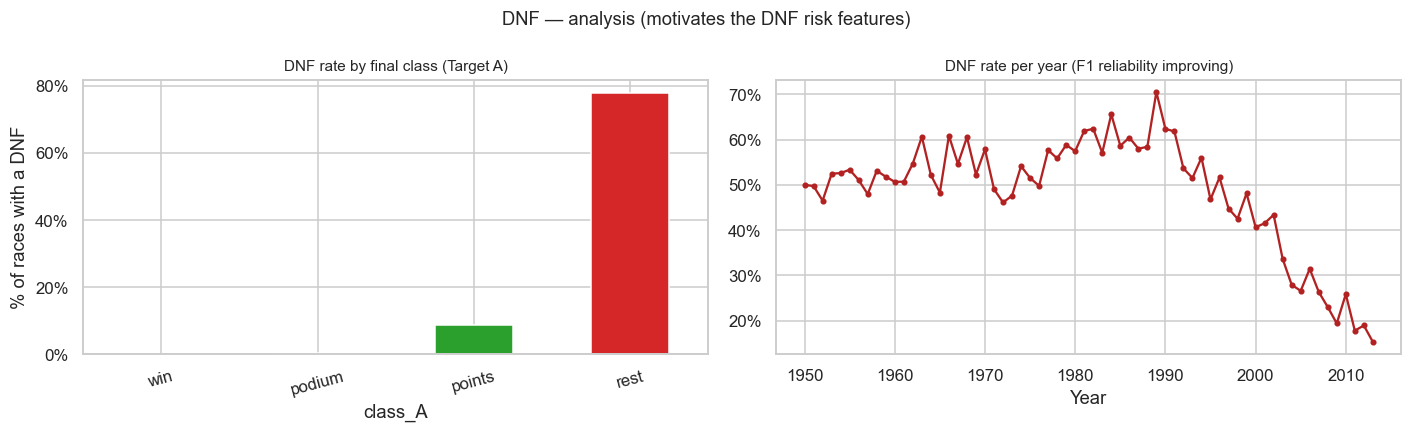

Mean DNF rate (train): 48.5%
Takeaway: DNFs heavily load the "rest" class -> historical DNF risk is a valuable feature.


In [9]:
# DNF (Did Not Finish): the driver did NOT reach a classified finish.
# Classified = 'Finished' (statusId==1) or '+N laps'; everything else = DNF/failure/collision/DNS/DNQ.
classified_tr = (train['statusId'] == 1) | train['status'].astype(str).str.startswith('+')
train_dnf = (~classified_tr).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
tmp = pd.DataFrame({'class_A': train['class_A'], 'dnf': train_dnf, 'year': train['year']})
dnf_by_cls = tmp.groupby('class_A')['dnf'].mean().reindex(CLASSES)
dnf_by_cls.plot(kind='bar', ax=axes[0], color=sns.color_palette('tab10', 4))
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].set_title('DNF rate by final class (Target A)', fontsize=10)
axes[0].set_ylabel('% of races with a DNF')
axes[0].tick_params(axis='x', rotation=15)

dnf_year = tmp.groupby('year')['dnf'].mean()
axes[1].plot(dnf_year.index, dnf_year.values, 'o-', ms=3, color='firebrick')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].set_title('DNF rate per year (F1 reliability improving)', fontsize=10)
axes[1].set_xlabel('Year')
plt.suptitle('DNF — analysis (motivates the DNF risk features)', fontsize=12)
plt.tight_layout()
plt.show()
print(f'Mean DNF rate (train): {train_dnf.mean():.1%}')
print('Takeaway: DNFs heavily load the "rest" class -> historical DNF risk is a valuable feature.')

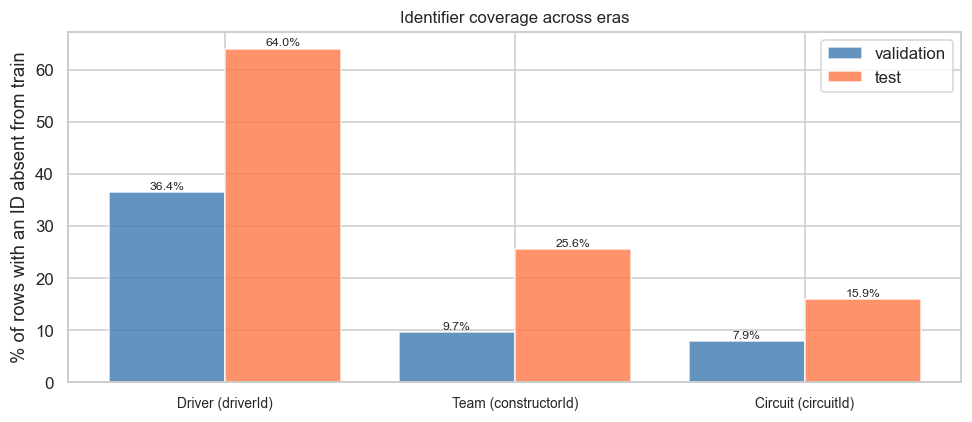

-> driverId: ~64% unknown in test — dropped from the features (noise)
-> constructorId, circuitId: frequency encoding (graceful degradation)


In [10]:
known_drivers      = set(train['driverId'].dropna())
known_constructors = set(train['constructorId'].dropna())
known_circuits     = set(train['circuitId'].dropna())

labels   = ['Driver (driverId)', 'Team (constructorId)', 'Circuit (circuitId)']
val_pct  = [
    (~val['driverId'].isin(known_drivers)).mean() * 100,
    (~val['constructorId'].isin(known_constructors)).mean() * 100,
    (~val['circuitId'].isin(known_circuits)).mean() * 100,
]
test_pct = [
    (~test['driverId'].isin(known_drivers)).mean() * 100,
    (~test['constructorId'].isin(known_constructors)).mean() * 100,
    (~test['circuitId'].isin(known_circuits)).mean() * 100,
]

x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, val_pct,  0.4, label='validation', color='steelblue', alpha=0.85)
ax.bar(x + 0.2, test_pct, 0.4, label='test',       color='coral',     alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('% of rows with an ID absent from train')
ax.set_title('Identifier coverage across eras', fontsize=11)
ax.legend()
for i, (v, t) in enumerate(zip(val_pct, test_pct)):
    ax.text(i - 0.2, v + 0.5, f'{v:.1f}%', ha='center', fontsize=8)
    ax.text(i + 0.2, t + 0.5, f'{t:.1f}%', ha='center', fontsize=8)
plt.tight_layout()
plt.show()
print('-> driverId: ~64% unknown in test — dropped from the features (noise)')
print('-> constructorId, circuitId: frequency encoding (graceful degradation)')

**Takeaways from the coverage analysis:**
- **`driverId`: 64% unknown in test** → raw `driverId` as a feature = noise. Dropped. Driver quality is carried by the historical features.
- **`constructorId` (25.6%), `circuitId` (15.9%):** frequency encoding — unknown IDs get 0 (neutral).
- **`nationality`:** low cardinality (~50 values) → OrdinalEncoder.

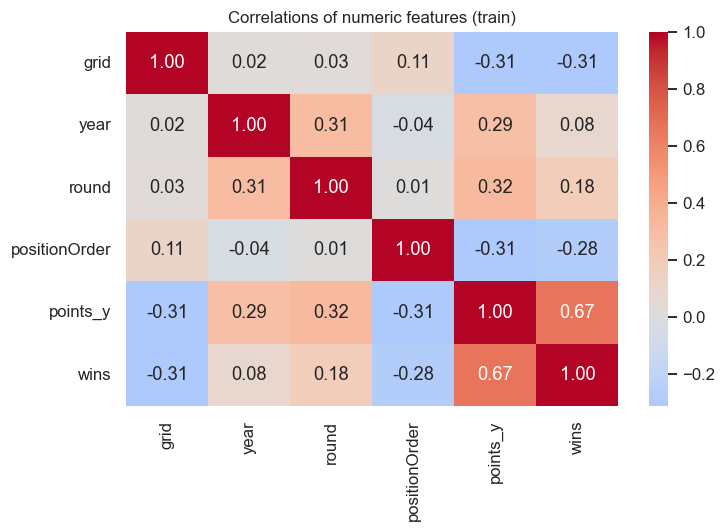

In [11]:
num_cols = ['grid', 'year', 'round', 'positionOrder', 'points_y', 'wins']
num_cols = [c for c in num_cols if c in train.columns]
corr = train[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlations of numeric features (train)', fontsize=11)
plt.tight_layout()
plt.show()

## 3. Feature engineering — WITHOUT data leakage

### Final feature list

| Feature | Rationale |
|---|---|
| `grid` | Starting position — known before the race |
| `year`, `round` | Time |
| `driver_age` | `(date - dob)` |
| `points_before` | Lag(`points_y`) **over the whole career** — standing before the race |
| `wins_before` | Lag(`wins`) over the whole career |
| `driver_form` | Rolling(5, shift=1) of `positionOrder` per driver |
| `career_experience` | Cumcount per `driverId` (career, not season) |
| `team_form` | Rolling(5, shift=1) of the mean `positionOrder` per team per race |
| `dnf_rate_career` | Share of unfinished races over the career (lagged) — failure/collision risk |
| `dnf_form_5` | DNF rate over the last 5 races (lagged) — current reliability |
| `chaos_circuit_hist` | Historical std(positionOrder−grid) per circuit (lagged) — proxy for wet/technical circuits |
| `is_wet_prone` | Binary flag: wet-prone circuits (Spa, Silverstone, Suzuka, Monaco, Interlagos) |
| `driver_circuit_form` | Driver's mean positionOrder AT THIS circuit (lagged) — track familiarity |
| `freq_constructor` | Frequency of `constructorId` in train (frequency encoding) |
| `freq_circuit` | Frequency of `circuitId` in train |
| `nationality` | OrdinalEncoder (low cardinality) |

**REMOVED:** `driverId` (64% unknown), `standing_before` (`position` not available in test), post-race variables.

In [12]:
train['split'] = 'train'
val['split']   = 'val'
test['split']  = 'test'

combined = pd.concat([train, val, test], ignore_index=True)
combined = combined.sort_values(['year', 'round']).reset_index(drop=True)

combined['driver_age'] = (combined['date'] - combined['dob']).dt.days / 365.25

# DNF flag (must be created BEFORE grouping, to feed the risk features)
classified = (combined['statusId'] == 1) | combined['status'].astype(str).str.startswith('+')
combined['dnf_flag'] = (~classified).astype(float)

# Career-long features — groupby driverId only (no reset each season)
grp_drv = combined.groupby('driverId', sort=False)
combined['points_before']     = grp_drv['points_y'].shift(1)
combined['wins_before']       = grp_drv['wins'].shift(1)
combined['career_experience'] = grp_drv.cumcount()
combined['driver_form'] = grp_drv['positionOrder'].transform(
    lambda x: x.shift(1).rolling(5, min_periods=1).mean()
)
# DNF risk — computed ONLY from earlier races (shift(1) -> no leakage)
combined['dnf_rate_career'] = grp_drv['dnf_flag'].transform(
    lambda x: x.shift(1).expanding().mean()
)
combined['dnf_form_5'] = grp_drv['dnf_flag'].transform(
    lambda x: x.shift(1).rolling(5, min_periods=1).mean()
)

# --- Circuit features (leakage-free) ---
# Historical chaos: std(positionOrder - grid) per race, lagged per circuit
# Captures: wet circuits, street circuits (Monaco), eras with mass failures
combined['_delta'] = combined['positionOrder'] - combined['grid'].fillna(9.0)
race_chaos_df = (combined.groupby(['year','round'])['_delta'].std()
                 .reset_index(name='race_chaos').sort_values(['year','round']))
combined.drop(columns=['_delta'], inplace=True)
circ_map = combined[['year','round','circuitId']].drop_duplicates()
race_chaos_df = race_chaos_df.merge(circ_map, on=['year','round'])
race_chaos_df['chaos_circuit_hist'] = (
    race_chaos_df.groupby('circuitId')['race_chaos']
    .transform(lambda x: x.shift(1).expanding().mean())
)
combined = combined.merge(
    race_chaos_df[['year','round','chaos_circuit_hist']], on=['year','round'], how='left'
)

# Wet / technical circuits — a priori expert knowledge (no leakage)
WET_GPS = {'Belgian Grand Prix','British Grand Prix','Japanese Grand Prix',
           'Brazilian Grand Prix','Monaco Grand Prix','Luxembourg Grand Prix'}
combined['is_wet_prone'] = combined['grand_prix'].isin(WET_GPS).astype(float)

# Driver form AT THIS circuit — expanding mean(positionOrder), shift(1)
combined['driver_circuit_form'] = (
    combined.groupby(['driverId','circuitId'])['positionOrder']
    .transform(lambda x: x.shift(1).expanding().mean())
)
print('Driver + circuit features ready.')

Driver + circuit features ready.


In [13]:
# Team form — mean positionOrder per race (avoids leakage within a race)
team_perf = (
    combined
    .groupby(['constructorId', 'year', 'round'])['positionOrder']
    .mean()
    .reset_index()
    .rename(columns={'positionOrder': 'team_avg_pos'})
    .sort_values(['year', 'round'])
)
team_perf['team_form'] = (
    team_perf.groupby('constructorId')['team_avg_pos']
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)
combined = combined.merge(
    team_perf[['constructorId', 'year', 'round', 'team_form']],
    on=['constructorId', 'year', 'round'], how='left'
)

# Frequency encoding — fitted ONLY on the training data
train_comb = combined[combined['split'] == 'train']
freq_constructor = train_comb['constructorId'].value_counts(normalize=True)
freq_circuit     = train_comb['circuitId'].value_counts(normalize=True)
combined['freq_constructor'] = combined['constructorId'].map(freq_constructor).fillna(0.0)
combined['freq_circuit']     = combined['circuitId'].map(freq_circuit).fillna(0.0)

train_fe = combined[combined['split'] == 'train'].copy()
val_fe   = combined[combined['split'] == 'val'].copy()
test_fe  = combined[combined['split'] == 'test'].copy()
print(f'train_fe: {train_fe.shape} | val_fe: {val_fe.shape} | test_fe: {test_fe.shape}')

train_fe: (21966, 72) | val_fe: (1836, 72) | test_fe: (2133, 72)


In [14]:
engineered_feats = [
    'driver_age', 'points_before', 'wins_before',
    'career_experience', 'driver_form', 'team_form',
    'dnf_rate_career', 'dnf_form_5',
    'chaos_circuit_hist', 'driver_circuit_form',
    'freq_constructor', 'freq_circuit'
]
print('Share of missing values in the engineered features (train_fe):')
missing_eng = train_fe[engineered_feats].isnull().mean().sort_values(ascending=False)
for col, pct in missing_eng.items():
    print(f'  {col:30s}: {pct*100:.2f}%')
print()
print('For comparison — old method (groupby driverId+year):')
print(f'  points_before: ~13.6% missing | career-long method: {missing_eng["points_before"]*100:.2f}%')

Share of missing values in the engineered features (train_fe):
  driver_circuit_form           : 32.66%
  chaos_circuit_hist            : 7.19%
  points_before                 : 5.18%
  wins_before                   : 5.18%
  driver_form                   : 3.71%
  dnf_rate_career               : 3.71%
  dnf_form_5                    : 3.71%
  team_form                     : 1.49%
  driver_age                    : 0.00%
  career_experience             : 0.00%
  freq_constructor              : 0.00%
  freq_circuit                  : 0.00%

For comparison — old method (groupby driverId+year):
  points_before: ~13.6% missing | career-long method: 5.18%


## 4. Preprocessing

In [15]:
NUM_FEATURES = [
    'grid', 'year', 'round', 'driver_age',
    'points_before', 'wins_before',
    'driver_form', 'career_experience',
    'team_form', 'dnf_rate_career', 'dnf_form_5',
    'chaos_circuit_hist', 'is_wet_prone', 'driver_circuit_form',
    'freq_constructor', 'freq_circuit'
]
CAT_FEATURES = ['nationality']
ALL_FEATURES = NUM_FEATURES + CAT_FEATURES
print(f'Features in total: {len(ALL_FEATURES)}')
print(f'  Numeric ({len(NUM_FEATURES)}): {NUM_FEATURES}')
print(f'  Categorical: {CAT_FEATURES}')
print()
print('New features (v3): chaos_circuit_hist, is_wet_prone, driver_circuit_form')
print('REMOVED: driverId (64% unknown in test), standing_before (missing in test)')

Features in total: 17
  Numeric (16): ['grid', 'year', 'round', 'driver_age', 'points_before', 'wins_before', 'driver_form', 'career_experience', 'team_form', 'dnf_rate_career', 'dnf_form_5', 'chaos_circuit_hist', 'is_wet_prone', 'driver_circuit_form', 'freq_constructor', 'freq_circuit']
  Categorical: ['nationality']

New features (v3): chaos_circuit_hist, is_wet_prone, driver_circuit_form
REMOVED: driverId (64% unknown in test), standing_before (missing in test)


In [16]:
def make_preproc_trees():
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), NUM_FEATURES),
        ('cat', Pipeline([
            ('imp', SimpleImputer(strategy='constant', fill_value='missing')),
            ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), CAT_FEATURES)
    ], remainder='drop')

def make_preproc_linear():
    return ColumnTransformer([
        ('num', Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('scl', StandardScaler())
        ]), NUM_FEATURES),
        ('cat', Pipeline([
            ('imp', SimpleImputer(strategy='constant', fill_value='missing')),
            ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), CAT_FEATURES)
    ], remainder='drop')

print('Preprocessor factories defined.')

Preprocessor factories defined.


In [17]:
def encode_target(s):
    return s.map({'win': 0, 'podium': 1, 'points': 2, 'rest': 3})

X_val  = val_fe[ALL_FEATURES]
y_val  = encode_target(val_fe['class_A'])
mask_val = y_val.notna()

X_test = test_fe[ALL_FEATURES]
y_test = encode_target(test_fe['class_A'])
mask_test = y_test.notna()

train_sorted = train_fe.sort_values(['year', 'round']).copy()
y_tr_raw = encode_target(train_sorted['class_A'])
train_sorted = train_sorted[y_tr_raw.notna()].copy()
X_tr = train_sorted[ALL_FEATURES]
y_tr = encode_target(train_sorted['class_A']).astype(int)

print(f'X_tr: {X_tr.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}')
print(f'Class distribution (train): {y_tr.value_counts().to_dict()}')

X_tr: (21966, 17) | X_val: (1836, 17) | X_test: (2133, 17)
Class distribution (train): {3: 12933, 2: 6321, 1: 1812, 0: 900}


In [18]:
tscv = TimeSeriesSplit(n_splits=5)
print(f'TimeSeriesSplit, 5 folds on {len(X_tr):,} samples.')
for i, (tr_idx, vl_idx) in enumerate(tscv.split(X_tr)):
    yr_tr = train_sorted.iloc[tr_idx]['year']
    print(f'  Fold {i+1}: train={len(tr_idx):,} ({yr_tr.min():.0f}-{yr_tr.max():.0f}), val={len(vl_idx):,}')

TimeSeriesSplit, 5 folds on 21,966 samples.
  Fold 1: train=3,661 (1950-1967), val=3,661
  Fold 2: train=7,322 (1950-1978), val=3,661
  Fold 3: train=10,983 (1950-1987), val=3,661
  Fold 4: train=14,644 (1950-1994), val=3,661
  Fold 5: train=18,305 (1950-2004), val=3,661


## 5. Modeling — Target A (`positionOrder`)

For each model: **`balanced`** (`class_weight='balanced'`) vs **`no_weights`**. The variant is chosen by macro-F1 on validation.

In [19]:
CLASS_NAMES = ['win', 'podium', 'points', 'rest']
results_val  = {}
results_test = {}

def report(name, y_true, y_pred, prefix='val'):
    mf1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    ba  = balanced_accuracy_score(y_true, y_pred)
    store = results_val if prefix == 'val' else results_test
    store[name] = {'mf1': mf1, 'ba': ba, 'pred': y_pred}
    print(f'--- {name} [{prefix}] ---')
    print(f'  Macro-F1: {mf1:.4f}  |  Balanced Acc: {ba:.4f}')
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))
    return mf1, ba

print('Evaluation functions ready.')

Evaluation functions ready.


In [20]:
def grid_rule(grid_vals):
    return np.where(grid_vals == 1, 0,
           np.where(grid_vals <= 3, 1,
           np.where(grid_vals <= 10, 2, 3)))

grid_val = X_val.loc[mask_val, 'grid'].fillna(99).values
pred_baseline = grid_rule(grid_val)
report('Grid_rule', y_val[mask_val].values, pred_baseline, 'val')

--- Grid_rule [val] ---
  Macro-F1: 0.6006  |  Balanced Acc: 0.6014
              precision    recall  f1-score   support

         win       0.57      0.57      0.57        88
      podium       0.45      0.47      0.46       178
      points       0.59      0.59      0.59       621
        rest       0.78      0.78      0.78       949

    accuracy                           0.67      1836
   macro avg       0.60      0.60      0.60      1836
weighted avg       0.67      0.67      0.67      1836



(0.6005628071263261, 0.6013785751821199)

In [21]:
pipe_lr_variants = {}
for cw, suffix in [('balanced', 'balanced'), (None, 'no_weights')]:
    pipe = Pipeline([
        ('prep', make_preproc_linear()),
        ('clf', LogisticRegression(class_weight=cw, max_iter=600, random_state=SEED))
    ])
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_val[mask_val])
    report(f'LR_{suffix}', y_val[mask_val].values, pred, 'val')
    pipe_lr_variants[suffix] = pipe

lr_winner = ('balanced' if results_val['LR_balanced']['mf1'] >= results_val['LR_no_weights']['mf1']
             else 'no_weights')
pipe_lr_best = pipe_lr_variants[lr_winner]
print(f'Selected LR variant: LR_{lr_winner} (F1={results_val["LR_" + lr_winner]["mf1"]:.4f})')

--- LR_balanced [val] ---
  Macro-F1: 0.5016  |  Balanced Acc: 0.5934
              precision    recall  f1-score   support

         win       0.33      0.84      0.48        88
      podium       0.26      0.40      0.32       178
      points       0.50      0.52      0.51       621
        rest       0.83      0.61      0.71       949

    accuracy                           0.57      1836
   macro avg       0.48      0.59      0.50      1836
weighted avg       0.64      0.57      0.59      1836



--- LR_no_weights [val] ---
  Macro-F1: 0.5310  |  Balanced Acc: 0.5310
              precision    recall  f1-score   support

         win       0.50      0.58      0.54        88
      podium       0.42      0.24      0.31       178
      points       0.54      0.48      0.51       621
        rest       0.72      0.82      0.77       949

    accuracy                           0.64      1836
   macro avg       0.55      0.53      0.53      1836
weighted avg       0.62      0.64      0.62      1836

Selected LR variant: LR_no_weights (F1=0.5310)


In [22]:
pipe_rf_variants = {}
for cw, suffix in [('balanced', 'balanced'), (None, 'no_weights')]:
    pipe = Pipeline([
        ('prep', make_preproc_trees()),
        ('clf', RandomForestClassifier(
            n_estimators=300, class_weight=cw, random_state=SEED, n_jobs=-1
        ))
    ])
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_val[mask_val])
    report(f'RF_{suffix}', y_val[mask_val].values, pred, 'val')
    pipe_rf_variants[suffix] = pipe

rf_winner = ('balanced' if results_val['RF_balanced']['mf1'] >= results_val['RF_no_weights']['mf1']
             else 'no_weights')
pipe_rf_best = pipe_rf_variants[rf_winner]
print(f'Selected RF variant: RF_{rf_winner} (F1={results_val["RF_" + rf_winner]["mf1"]:.4f})')

--- RF_balanced [val] ---
  Macro-F1: 0.5137  |  Balanced Acc: 0.5162
              precision    recall  f1-score   support

         win       0.49      0.56      0.52        88
      podium       0.48      0.13      0.20       178
      points       0.54      0.55      0.54       621
        rest       0.74      0.83      0.79       949

    accuracy                           0.65      1836
   macro avg       0.56      0.52      0.51      1836
weighted avg       0.64      0.65      0.63      1836



--- RF_no_weights [val] ---
  Macro-F1: 0.5304  |  Balanced Acc: 0.5469
              precision    recall  f1-score   support

         win       0.47      0.65      0.55        88
      podium       0.51      0.13      0.21       178
      points       0.56      0.59      0.58       621
        rest       0.76      0.82      0.79       949

    accuracy                           0.67      1836
   macro avg       0.58      0.55      0.53      1836
weighted avg       0.66      0.67      0.65      1836

Selected RF variant: RF_no_weights (F1=0.5304)


In [23]:
pipe_boost_variants = {}
for cw, suffix in [('balanced', 'balanced'), (None, 'no_weights')]:
    if BOOST_TYPE == 'LGB':
        clf = LGBMClassifier(
            n_estimators=400, max_depth=3, learning_rate=0.03,
            num_leaves=8, subsample=0.8, colsample_bytree=0.8,
            reg_lambda=5, min_child_samples=50,
            class_weight=cw, random_state=SEED, n_jobs=-1, verbose=-1
        )
        pipe = Pipeline([('prep', make_preproc_trees()), ('clf', clf)])
        pipe.fit(X_tr, y_tr)
    else:
        clf = XGBClassifier(
            n_estimators=400, max_depth=3, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=5, min_child_weight=10,
            num_class=4, objective='multi:softmax', eval_metric='mlogloss',
            random_state=SEED, n_jobs=-1, verbosity=0
        )
        pipe = Pipeline([('prep', make_preproc_trees()), ('clf', clf)])
        if cw == 'balanced':
            sw = compute_sample_weight('balanced', y_tr)
            pipe.fit(X_tr, y_tr, clf__sample_weight=sw)
        else:
            pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_val[mask_val])
    report(f'{BOOST_TYPE}_{suffix}', y_val[mask_val].values, pred, 'val')
    pipe_boost_variants[suffix] = pipe

boost_bal_f1   = results_val[f'{BOOST_TYPE}_balanced']['mf1']
boost_nobal_f1 = results_val[f'{BOOST_TYPE}_no_weights']['mf1']
boost_winner   = 'balanced' if boost_bal_f1 >= boost_nobal_f1 else 'no_weights'
pipe_boost_best = pipe_boost_variants[boost_winner]
boost_cw_best   = 'balanced' if boost_winner == 'balanced' else None
# Global keys — used in later cells
lr_key    = f'LR_{lr_winner}'
rf_key    = f'RF_{rf_winner}'
boost_key = f'{BOOST_TYPE}_{boost_winner}'
print(f'Selected {BOOST_TYPE} variant: {boost_key} (F1={results_val[boost_key]["mf1"]:.4f})')

--- LGB_balanced [val] ---
  Macro-F1: 0.5461  |  Balanced Acc: 0.6145
              precision    recall  f1-score   support

         win       0.39      0.82      0.53        88
      podium       0.32      0.35      0.34       178
      points       0.54      0.66      0.59       621
        rest       0.86      0.63      0.73       949

    accuracy                           0.62      1836
   macro avg       0.53      0.61      0.55      1836
weighted avg       0.68      0.62      0.64      1836



--- LGB_no_weights [val] ---
  Macro-F1: 0.5117  |  Balanced Acc: 0.5391
              precision    recall  f1-score   support

         win       0.48      0.67      0.56        88
      podium       0.38      0.07      0.12       178
      points       0.55      0.60      0.57       621
        rest       0.77      0.81      0.79       949

    accuracy                           0.66      1836
   macro avg       0.55      0.54      0.51      1836
weighted avg       0.64      0.66      0.64      1836

Selected LGB variant: LGB_balanced (F1=0.5461)


### 5b. Class-threshold calibration (post-processing, no extra training)
Minority classes (win 4%, podium 8%) are systematically under-predicted by `argmax(proba)`.
Trick: instead of `argmax(p)` we use `argmax(p × w)` — the weights `w` are optimised with Nelder-Mead on **validation**
for macro-F1 only. We do not touch the model, we only reinterpret its probabilities.

*Beware of evaluation leakage:* the weights are fitted to validation → they can overfit it;
that is why the final verdict is given on the **test** set (2018–2023).

In [24]:
proba_boost_val = pipe_boost_best.predict_proba(X_val[mask_val])
y_calib_true    = y_val[mask_val].values

if HAS_SCIPY:
    def neg_macro_f1_w(w):
        pred = (proba_boost_val * np.maximum(w, 0.05)).argmax(axis=1)
        return -f1_score(y_calib_true, pred, average='macro', zero_division=0)

    res = scipy_minimize(neg_macro_f1_w, x0=[1.5, 2.0, 1.0, 1.0], method='Nelder-Mead',
                         options={'maxiter': 8000, 'xatol': 1e-6, 'fatol': 1e-6})
    opt_weights = np.maximum(res.x, 0.05)
    print(f'Optimal class weights:')
    for i, (cls, w) in enumerate(zip(CLASS_NAMES, opt_weights)):
        print(f'  {cls:8s}: {w:.3f}')
    print(f'Macro-F1 (optimisation): {-res.fun:.4f}')
else:
    opt_weights = np.array([1.5, 2.0, 1.0, 1.0])
    print('scipy not available, heuristic weights:', opt_weights)

pred_calib_val = (proba_boost_val * opt_weights).argmax(axis=1)
report(f'{boost_key}_calib', y_calib_true, pred_calib_val, 'val')

Optimal class weights:
  win     : 1.089
  podium  : 2.002
  points  : 1.057
  rest    : 1.227
Macro-F1 (optimisation): 0.5705
--- LGB_balanced_calib [val] ---
  Macro-F1: 0.5705  |  Balanced Acc: 0.6432
              precision    recall  f1-score   support

         win       0.51      0.74      0.60        88
      podium       0.29      0.67      0.41       178
      points       0.55      0.49      0.52       621
        rest       0.86      0.67      0.76       949

    accuracy                           0.61      1836
   macro avg       0.55      0.64      0.57      1836
weighted avg       0.68      0.61      0.63      1836



(0.5705178154687143, 0.6431782764402418)

### 5c. Hierarchical model (2-level cascade)
Goal: the **podium** class is the weakest (see the error analysis in section 7).

Architecture:
1. **Stage 1 (binary):** rest (>10) vs top-10 — a simpler problem, the model can reach higher recall.
   We use an aggressive threshold P(top-10) ≥ θ to limit missed podiums / wins.
2. **Stage 2 (3-class):** for rows classified as top-10 → win / podium / points.

Both stages are independent LGB/XGB models (same hyperparameters), trained on the same feature set.

--- Hierarchical [val] ---
  Macro-F1: 0.5628  |  Balanced Acc: 0.6209
              precision    recall  f1-score   support

         win       0.42      0.78      0.54        88
      podium       0.33      0.40      0.36       178
      points       0.56      0.60      0.58       621
        rest       0.83      0.70      0.76       949

    accuracy                           0.64      1836
   macro avg       0.54      0.62      0.56      1836
weighted avg       0.67      0.64      0.65      1836



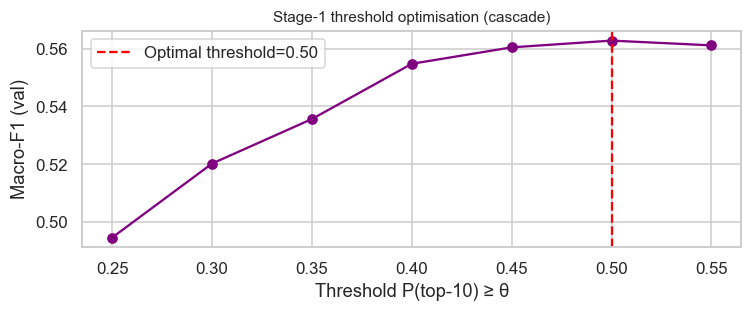

Optimal threshold: 0.50 | Hierarchical val F1: 0.5628


In [25]:
# Stage 1 — binary: rest=0 vs top-10=1
y_bin_tr = (y_tr < 3).astype(int)

if BOOST_TYPE == 'LGB':
    clf_s1 = LGBMClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        num_leaves=8, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=5, min_child_samples=50,
        class_weight='balanced', random_state=SEED, n_jobs=-1, verbose=-1
    )
    clf_s2 = LGBMClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        num_leaves=8, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=5, min_child_samples=20,
        class_weight='balanced', random_state=SEED, n_jobs=-1, verbose=-1
    )
else:
    clf_s1 = XGBClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5, min_child_weight=10,
        objective='binary:logistic', eval_metric='logloss',
        random_state=SEED, n_jobs=-1, verbosity=0
    )
    clf_s2 = XGBClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5, min_child_weight=5,
        num_class=3, objective='multi:softmax', eval_metric='mlogloss',
        random_state=SEED, n_jobs=-1, verbosity=0
    )

pipe_s1 = Pipeline([('prep', make_preproc_trees()), ('clf', clf_s1)])
pipe_s1.fit(X_tr, y_bin_tr)

idx_top10_tr = y_tr < 3
pipe_s2 = Pipeline([('prep', make_preproc_trees()), ('clf', clf_s2)])
if BOOST_TYPE == 'XGB':
    sw2 = compute_sample_weight('balanced', y_tr.loc[idx_top10_tr])
    pipe_s2.fit(X_tr.loc[idx_top10_tr], y_tr.loc[idx_top10_tr], clf__sample_weight=sw2)
else:
    pipe_s2.fit(X_tr.loc[idx_top10_tr], y_tr.loc[idx_top10_tr])

def predict_hierarchical(X, threshold=0.35):
    p_top10  = pipe_s1.predict_proba(X)[:,1]
    pred_s2  = pipe_s2.predict(X)
    return np.where(p_top10 >= threshold, pred_s2, 3)

# Threshold optimisation on validation
thresholds = np.arange(0.25, 0.60, 0.05)
f1_by_threshold = [f1_score(y_val[mask_val].values,
                            predict_hierarchical(X_val[mask_val], t),
                            average='macro', zero_division=0) for t in thresholds]
best_threshold = thresholds[int(np.argmax(f1_by_threshold))]
pred_hier_opt_val = predict_hierarchical(X_val[mask_val], best_threshold)
report('Hierarchical', y_val[mask_val].values, pred_hier_opt_val, 'val')

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(thresholds, f1_by_threshold, 'o-', color='purple')
ax.axvline(best_threshold, ls='--', color='red', label=f'Optimal threshold={best_threshold:.2f}')
ax.set_xlabel('Threshold P(top-10) ≥ θ')
ax.set_ylabel('Macro-F1 (val)')
ax.set_title('Stage-1 threshold optimisation (cascade)', fontsize=10)
ax.legend(); plt.tight_layout(); plt.show()
print(f'Optimal threshold: {best_threshold:.2f} | Hierarchical val F1: {max(f1_by_threshold):.4f}')

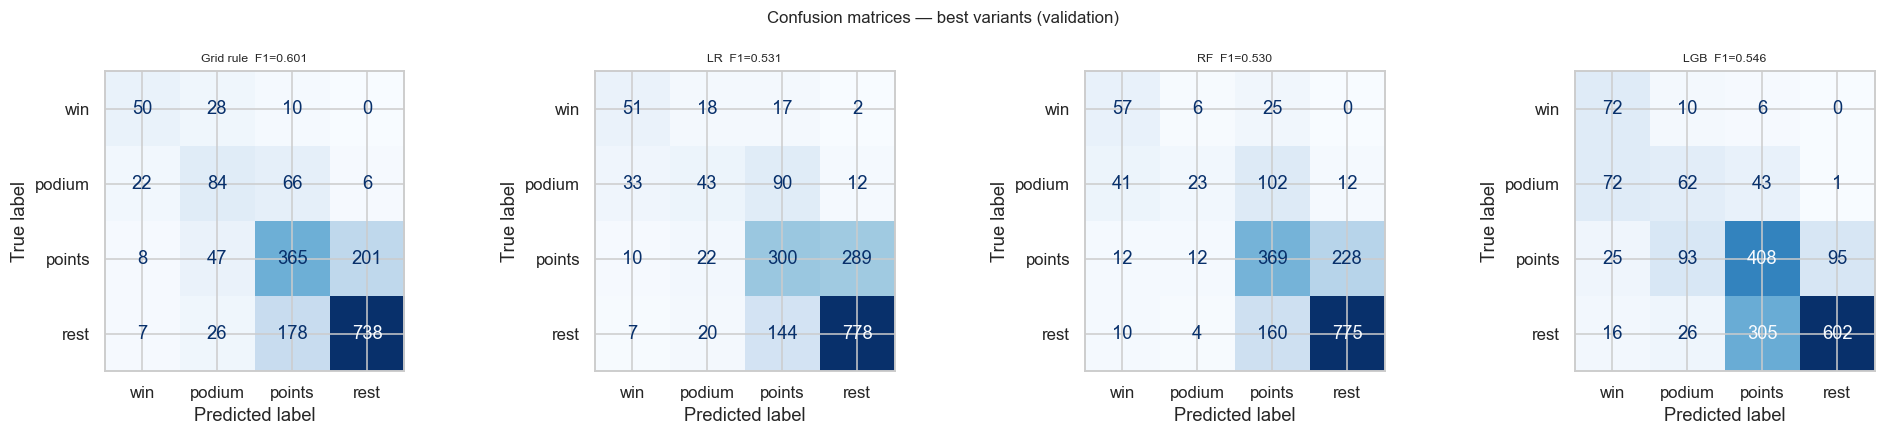

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, key) in zip(axes, [
    ('Grid rule',      'Grid_rule'),
    (f'LR',            lr_key),
    (f'RF',            rf_key),
    (BOOST_TYPE,       boost_key),
]):
    ConfusionMatrixDisplay.from_predictions(
        y_val[mask_val].values, results_val[key]['pred'],
        display_labels=CLASS_NAMES, cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(f'{title}  F1={results_val[key]["mf1"]:.3f}', fontsize=8)
plt.suptitle('Confusion matrices — best variants (validation)', fontsize=11)
plt.tight_layout()
plt.show()

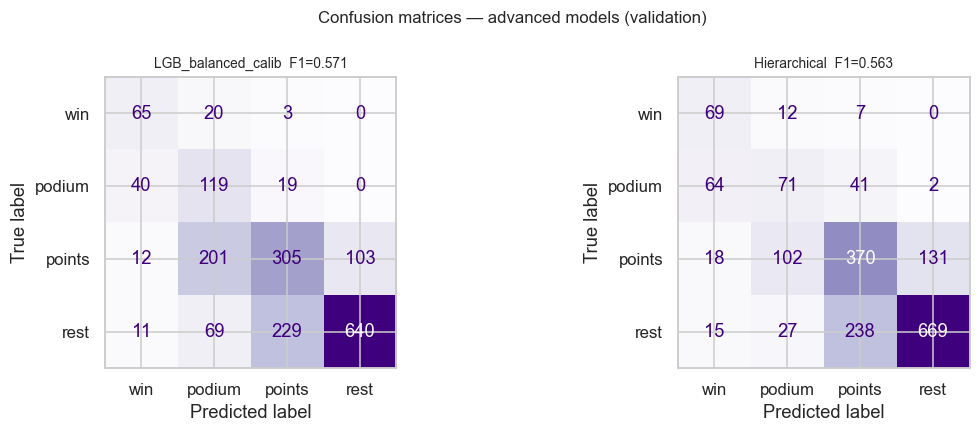

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key in zip(axes, [f'{boost_key}_calib', 'Hierarchical']):
    if key in results_val:
        ConfusionMatrixDisplay.from_predictions(
            y_val[mask_val].values, results_val[key]['pred'],
            display_labels=CLASS_NAMES, cmap='Purples', ax=ax, colorbar=False
        )
        ax.set_title(f'{key}  F1={results_val[key]["mf1"]:.3f}', fontsize=9)
plt.suptitle('Confusion matrices — advanced models (validation)', fontsize=11)
plt.tight_layout()
plt.show()

=== MODEL COMPARISON — VALIDATION ===
             Model  Macro-F1  Balanced Acc vs baseline
         Grid_rule    0.6006        0.6014       equal
LGB_balanced_calib    0.5705        0.6432       below
      Hierarchical    0.5628        0.6209       below
      LGB_balanced    0.5461        0.6145       below
     LR_no_weights    0.5310        0.5310       below
     RF_no_weights    0.5304        0.5469       below
       RF_balanced    0.5137        0.5162       below
    LGB_no_weights    0.5117        0.5391       below
       LR_balanced    0.5016        0.5934       below


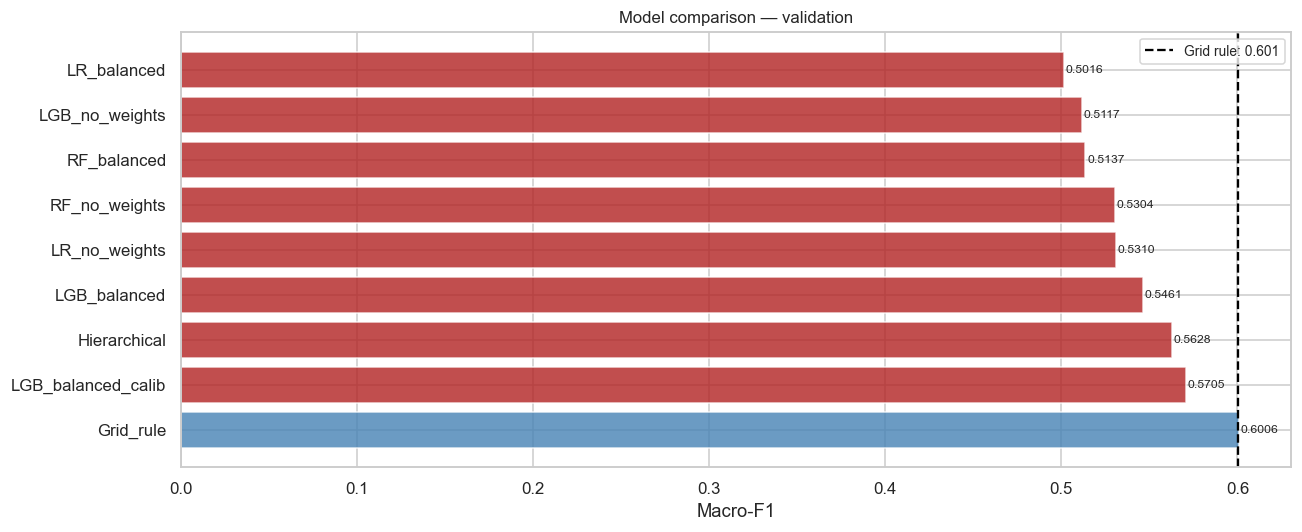

In [28]:
baseline_f1 = results_val['Grid_rule']['mf1']
rows = []
for name, res in results_val.items():
    vs = ('beats' if res['mf1'] > baseline_f1 + 0.001
          else ('below' if res['mf1'] < baseline_f1 - 0.001 else 'equal'))
    rows.append({'Model': name, 'Macro-F1': round(res['mf1'], 4),
                 'Balanced Acc': round(res['ba'], 4), 'vs baseline': vs})

df_comp = pd.DataFrame(rows).sort_values('Macro-F1', ascending=False)
print('=== MODEL COMPARISON — VALIDATION ===')
print(df_comp.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 5))
colors = [
    'forestgreen' if r['vs baseline'] == 'beats' else
    'firebrick'   if r['vs baseline'] == 'below' else 'steelblue'
    for _, r in df_comp.iterrows()
]
ax.barh(df_comp['Model'], df_comp['Macro-F1'], color=colors, alpha=0.8)
ax.axvline(baseline_f1, color='black', ls='--', lw=1.5,
           label=f'Grid rule: {baseline_f1:.3f}')
for bar in ax.patches:
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{bar.get_width():.4f}', va='center', fontsize=8)
ax.set_xlabel('Macro-F1')
ax.set_title('Model comparison — validation', fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 6. "Recency" experiment — the effect of era drift
The best model trained on the **full 1950–2013 data** vs **restricted to 2000–2013**.

In [29]:
mask_recent = (train_sorted['year'] >= 2000).values
X_tr_recent = X_tr.iloc[mask_recent]
y_tr_recent = y_tr.iloc[mask_recent]
print(f'Full train: {len(X_tr):,} | Recency 2000-2013: {len(X_tr_recent):,}')

if BOOST_TYPE == 'LGB':
    clf_rec = LGBMClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        num_leaves=8, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=5, min_child_samples=50,
        class_weight=boost_cw_best, random_state=SEED, n_jobs=-1, verbose=-1
    )
    pipe_recency = Pipeline([('prep', make_preproc_trees()), ('clf', clf_rec)])
    pipe_recency.fit(X_tr_recent, y_tr_recent)
else:
    clf_rec = XGBClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5, min_child_weight=10,
        num_class=4, objective='multi:softmax', eval_metric='mlogloss',
        random_state=SEED, n_jobs=-1, verbosity=0
    )
    pipe_recency = Pipeline([('prep', make_preproc_trees()), ('clf', clf_rec)])
    if boost_cw_best == 'balanced':
        sw_rec = compute_sample_weight('balanced', y_tr_recent)
        pipe_recency.fit(X_tr_recent, y_tr_recent, clf__sample_weight=sw_rec)
    else:
        pipe_recency.fit(X_tr_recent, y_tr_recent)

pred_rec_val  = pipe_recency.predict(X_val[mask_val])
mf1_rec_val   = f1_score(y_val[mask_val].values, pred_rec_val,   average='macro', zero_division=0)
pred_rec_test = pipe_recency.predict(X_test[mask_test])
mf1_rec_test  = f1_score(y_test[mask_test].values, pred_rec_test, average='macro', zero_division=0)
mf1_full_val  = results_val[boost_key]['mf1']

print(f'{BOOST_TYPE} full    (1950-2013): val F1 = {mf1_full_val:.4f}')
print(f'{BOOST_TYPE} recency (2000-2013): val F1 = {mf1_rec_val:.4f}')
print(f'{BOOST_TYPE} recency (on test):   test F1 = {mf1_rec_test:.4f}')

Full train: 21,966 | Recency 2000-2013: 5,392


LGB full    (1950-2013): val F1 = 0.5461
LGB recency (2000-2013): val F1 = 0.5472
LGB recency (on test):   test F1 = 0.4868


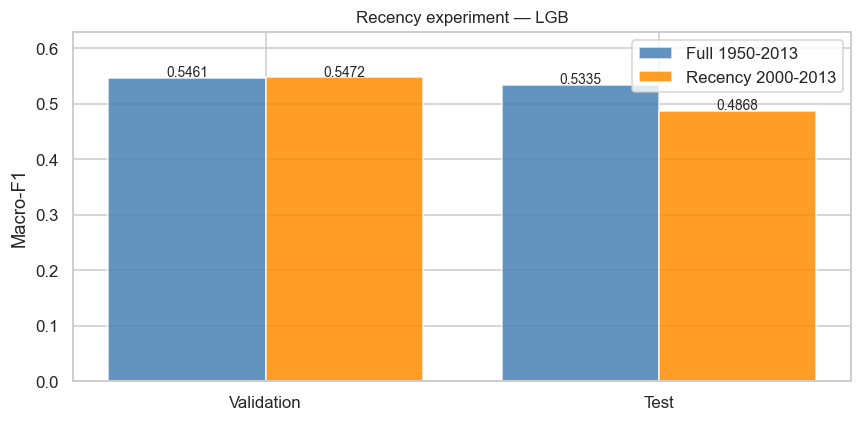

Takeaway: the full model wins on test -> older history still carries useful signal.


In [30]:
pred_full_test = pipe_boost_best.predict(X_test[mask_test])
mf1_full_test  = f1_score(y_test[mask_test].values, pred_full_test, average='macro', zero_division=0)

fig, ax = plt.subplots(figsize=(8, 4))
cats = ['Validation', 'Test']
vals_full   = [mf1_full_val,  mf1_full_test]
vals_recent = [mf1_rec_val,   mf1_rec_test]
x = np.arange(2)
ax.bar(x - 0.2, vals_full,   0.4, label='Full 1950-2013', color='steelblue', alpha=0.85)
ax.bar(x + 0.2, vals_recent, 0.4, label='Recency 2000-2013', color='darkorange', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(cats)
ax.set_ylabel('Macro-F1')
ax.set_title(f'Recency experiment — {BOOST_TYPE}', fontsize=11)
ax.legend()
for i, (f, r) in enumerate(zip(vals_full, vals_recent)):
    ax.text(i - 0.2, f + 0.002, f'{f:.4f}', ha='center', fontsize=9)
    ax.text(i + 0.2, r + 0.002, f'{r:.4f}', ha='center', fontsize=9)
ax.set_ylim(0, max(vals_full + vals_recent) * 1.15)
plt.tight_layout()
plt.show()
if mf1_rec_test > mf1_full_test:
    print('Takeaway: recency beats the full model on test -> pre-2000 data adds noise (different eras).')
else:
    print('Takeaway: the full model wins on test -> older history still carries useful signal.')

## 7. Error analysis and feature importance

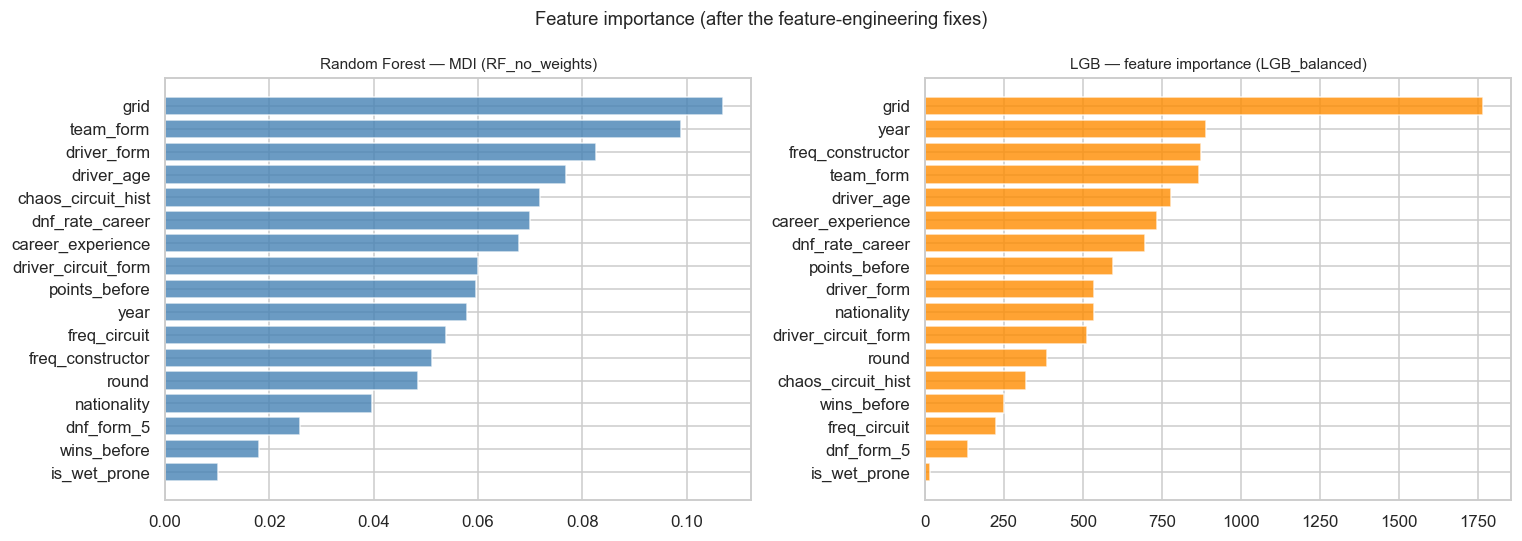

Dominant feature: grid


In [31]:
feature_names = NUM_FEATURES + CAT_FEATURES
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

imp_rf = pipe_rf_best.named_steps['clf'].feature_importances_
fi_rf  = pd.DataFrame({'feature': feature_names, 'importance': imp_rf}).sort_values('importance')
axes[0].barh(fi_rf['feature'], fi_rf['importance'], color='steelblue', alpha=0.8)
axes[0].set_title(f'Random Forest — MDI (RF_{rf_winner})', fontsize=10)

imp_boost = pipe_boost_best.named_steps['clf'].feature_importances_
fi_boost  = pd.DataFrame({'feature': feature_names, 'importance': imp_boost}).sort_values('importance')
axes[1].barh(fi_boost['feature'], fi_boost['importance'], color='darkorange', alpha=0.8)
axes[1].set_title(f'{BOOST_TYPE} — feature importance ({BOOST_TYPE}_{boost_winner})', fontsize=10)

plt.suptitle('Feature importance (after the feature-engineering fixes)', fontsize=12)
plt.tight_layout()
plt.show()
top_feat = fi_boost.sort_values('importance', ascending=False).iloc[0]['feature']
print(f'Dominant feature: {top_feat}')

In [32]:
y_true_arr = y_val[mask_val].values
best_pred  = results_val[boost_key]['pred']
print(f'Error analysis — {boost_key} (validation):')
print(f'{"Class":12s} | {"N":6s} | {"Recall":8s} | Most common error')
print('-' * 55)
for cls_i, cls_name in enumerate(CLASS_NAMES):
    mask_c = y_true_arr == cls_i
    n = mask_c.sum()
    if n == 0:
        continue
    recall = (best_pred[mask_c] == cls_i).mean()
    errs = best_pred[mask_c][best_pred[mask_c] != cls_i]
    mce = CLASS_NAMES[int(pd.Series(errs).mode().iloc[0])] if len(errs) > 0 else '-'
    print(f'{cls_name:12s} | {n:6d} | {recall:.2%}   | {mce}')

Error analysis — LGB_balanced (validation):
Class        | N      | Recall   | Most common error
-------------------------------------------------------
win          |     88 | 81.82%   | podium
podium       |    178 | 34.83%   | win
points       |    621 | 65.70%   | rest
rest         |    949 | 63.44%   | points


## 8. Evaluation on the test set (2018–2023)

=== TEST SET EVALUATION ===


--- Grid_rule [test] ---
  Macro-F1: 0.5532  |  Balanced Acc: 0.5616
              precision    recall  f1-score   support

         win       0.49      0.49      0.49       106
      podium       0.38      0.47      0.42       212
      points       0.58      0.58      0.58       745
        rest       0.75      0.71      0.73      1070

    accuracy                           0.63      2133
   macro avg       0.55      0.56      0.55      2133
weighted avg       0.64      0.63      0.63      2133

--- LR_no_weights [test] ---
  Macro-F1: 0.5357  |  Balanced Acc: 0.5295
              precision    recall  f1-score   support

         win       0.56      0.58      0.57       106
      podium       0.45      0.27      0.34       212
      points       0.52      0.47      0.49       745
        rest       0.70      0.80      0.74      1070

    accuracy                           0.62      2133
   macro avg       0.56      0.53      0.54      2133
weighted avg       0.60      0.62      0.61

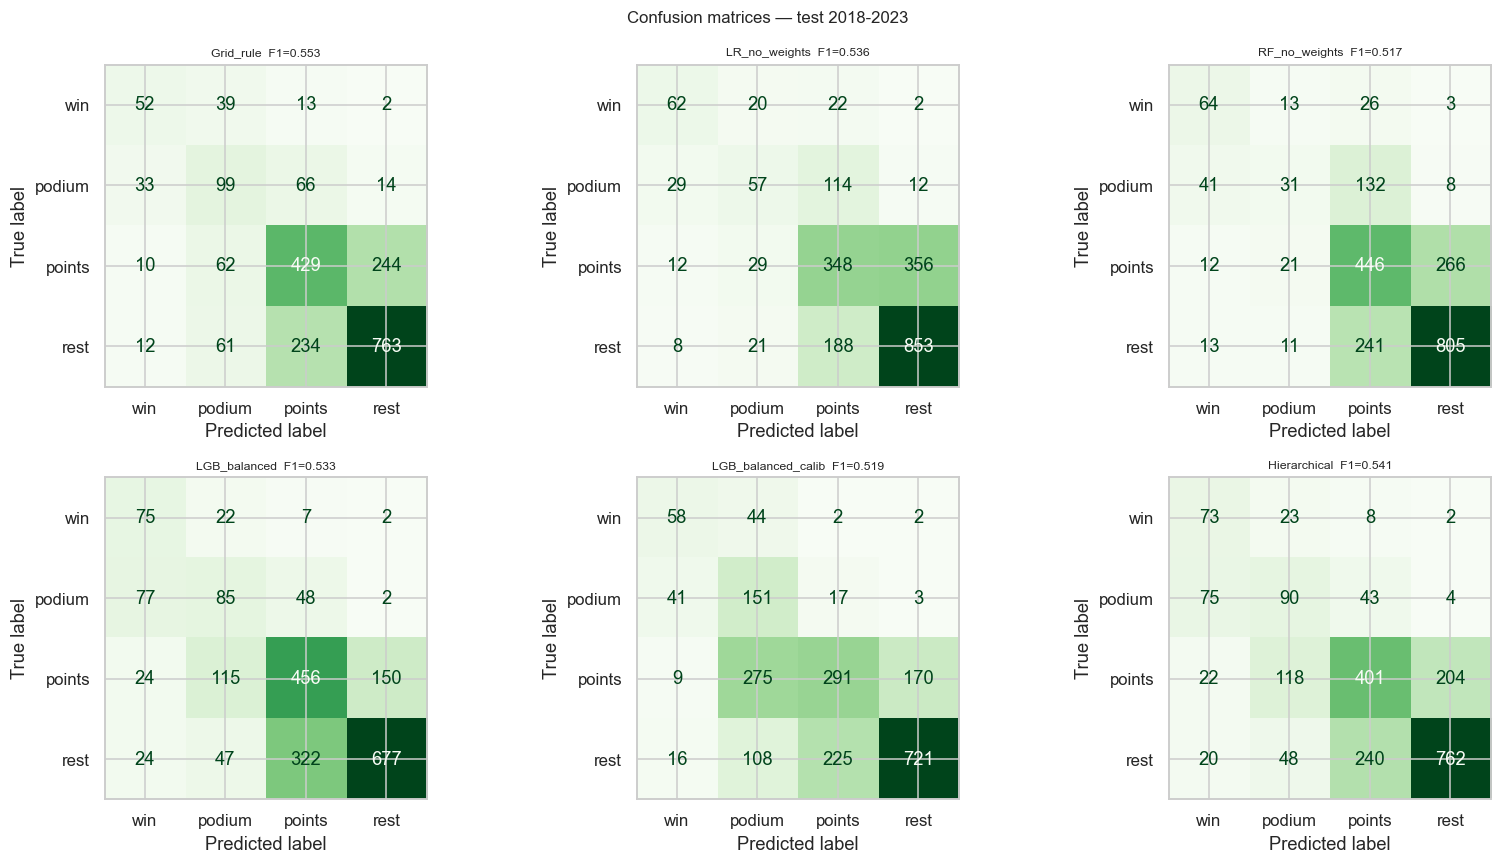

In [33]:
print('=== TEST SET EVALUATION ===')
grid_test = X_test.loc[mask_test, 'grid'].fillna(99).values
report('Grid_rule', y_test[mask_test].values, grid_rule(grid_test), 'test')

for key, pipe in [(lr_key, pipe_lr_best), (rf_key, pipe_rf_best), (boost_key, pipe_boost_best)]:
    pred = pipe.predict(X_test[mask_test])
    report(key, y_test[mask_test].values, pred, 'test')

# Threshold calibration on test (weights optimised on validation)
proba_boost_test = pipe_boost_best.predict_proba(X_test[mask_test])
pred_calib_test  = (proba_boost_test * opt_weights).argmax(axis=1)
report(f'{boost_key}_calib', y_test[mask_test].values, pred_calib_test, 'test')

# Hierarchical on test
pred_hier_test = predict_hierarchical(X_test[mask_test], best_threshold)
report('Hierarchical', y_test[mask_test].values, pred_hier_test, 'test')

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for ax, key in zip(axes, ['Grid_rule', lr_key, rf_key, boost_key,
                          f'{boost_key}_calib', 'Hierarchical']):
    ConfusionMatrixDisplay.from_predictions(
        y_test[mask_test].values, results_test[key]['pred'],
        display_labels=CLASS_NAMES, cmap='Greens', ax=ax, colorbar=False
    )
    ax.set_title(f'{key}  F1={results_test[key]["mf1"]:.3f}', fontsize=8)
plt.suptitle('Confusion matrices — test 2018-2023', fontsize=11)
plt.tight_layout()
plt.show()

In [34]:
print('=== SUMMARY TABLE OF RESULTS ===')
hdr = f'{"Model":35s} | {"Val F1":7s} | {"Val BA":7s} | {"Test F1":8s} | {"Test BA":7s}'
print(hdr)
print('-' * len(hdr))
order = ['Grid_rule', lr_key, rf_key, boost_key,
         f'{boost_key}_calib', 'Hierarchical']
for name in order:
    v = results_val.get(name, {})
    t = results_test.get(name, {})
    marker = ' <--' if name in (f'{boost_key}_calib','Hierarchical') else ''
    print(f'{name:35s} | {v.get("mf1",0):.4f}  | {v.get("ba",0):.4f}  '
          f'| {t.get("mf1",0):.4f}   | {t.get("ba",0):.4f}{marker}')
print()
best_val = max(order, key=lambda k: results_val.get(k,{}).get('mf1',0))
best_test = max(order, key=lambda k: results_test.get(k,{}).get('mf1',0))
print(f'Best on val:  {best_val} (F1={results_val[best_val]["mf1"]:.4f})')
print(f'Best on test: {best_test} (F1={results_test[best_test]["mf1"]:.4f})')

=== SUMMARY TABLE OF RESULTS ===
Model                               | Val F1  | Val BA  | Test F1  | Test BA
----------------------------------------------------------------------------
Grid_rule                           | 0.6006  | 0.6014  | 0.5532   | 0.5616
LR_no_weights                       | 0.5310  | 0.5310  | 0.5357   | 0.5295
RF_no_weights                       | 0.5304  | 0.5469  | 0.5167   | 0.5252
LGB_balanced                        | 0.5461  | 0.6145  | 0.5335   | 0.5883
LGB_balanced_calib                  | 0.5705  | 0.6432  | 0.5187   | 0.5810 <--
Hierarchical                        | 0.5628  | 0.6209  | 0.5411   | 0.5909 <--

Best on val:  Grid_rule (F1=0.6006)
Best on test: Grid_rule (F1=0.5532)


In [35]:
best_test_name = max(results_test, key=lambda k: results_test[k]['mf1'])
best_test_pred = np.array(results_test[best_test_name]['pred'])
class_map = {0: 'win', 1: 'podium', 2: 'points', 3: 'rest'}
test_sub = test_fe[mask_test].copy()

submission = pd.DataFrame({
    'result_driver_standing': test_sub['result_driver_standing'].values,
    'predicted_class':        [class_map[p] for p in best_test_pred],
    'class_numeric':          best_test_pred,
    'true_class':             [class_map[p] for p in y_test[mask_test].values]
})
submission.to_csv(DATA_DIR / 'predictions_target_A.csv', index=False)
print(f'Saved {len(submission):,} predictions.')
print(f'Model: {best_test_name} | Test Macro-F1: {results_test[best_test_name]["mf1"]:.4f}')
print('Prediction distribution:', submission['predicted_class'].value_counts().to_dict())
print()
print('[Note] sample_submission.csv expects a numeric position;')
print('we return the 4-level class (class_numeric: 0=win..3=rest)')

Saved 2,133 predictions.
Model: Grid_rule | Test Macro-F1: 0.5532
Prediction distribution: {'rest': 1023, 'points': 742, 'podium': 261, 'win': 107}

[Note] sample_submission.csv expects a numeric position;
we return the 4-level class (class_numeric: 0=win..3=rest)


## 9. Conclusions

### Main findings

**Do the models beat the grid rule? (honest answer: close, but no)**
`grid` is the dominant predictor, and the class boundaries (1 / 2–3 / 4–10 / >10) **coincide with bands of the starting
position** — which is why the trivial "grid → class" rule is an exceptionally strong baseline (macro-F1 0.6006 on val,
0.5532 on test). After regularisation (shallow trees `max_depth=3`, `reg_lambda=5`) class weights raise boosting's
macro-F1 on val from 0.51 to 0.55 and lift the weakest class, **podium**, from F1 0.12 to 0.34 — still below the rule's
podium F1 (0.46). Reasons: (1) dominance of `grid`, (2) the classes align with grid bands, (3) strong drift 1950–2023,
(4) irreducible randomness (failures/DNFs, weather). This is a valuable methodological takeaway: **not every problem needs
ML** — here a simple, interpretable baseline is hard to beat, and a model should be reported next to it, not instead of it.

**Bottleneck:** the **podium** class (recall ≈ 35% for the best boosting variant on val) — most often confused with
**win**, i.e. the model struggles to separate P1 from P2–P3. This is the main area for further improvement
(e.g. a dedicated binary podium model, qualifying/pace features).

**Strongest features:** `grid`, `team_form`, `driver_form`, `points_before`, DNF risk.

**Class weights:** The balanced / no_weights comparison shows the trade-off between rare classes (win 4%, podium 8%) and the dominant one (rest 58%). Macro-F1 rewards better balance.

**Recency experiment:** The model trained on 2000–2013 is worse on test 2018–2023 than the model trained on 1950–2013
(0.4868 vs 0.5335). Less drift does not make up for the smaller training set — older history still carries signal.

**DNF risk:** the features `dnf_rate_career` and `dnf_form_5` (lagged share of unfinished races) describe
driver/car reliability. DNFs heavily load the "rest" class (a driver from the front of the grid who does not finish
ends up at the back) — DNF history helps the model with cases that `grid` alone does not explain.

**Circuit features (v3):**
- `chaos_circuit_hist` — historical std(positionOrder−grid) per circuit (lagged). High-chaos circuits
  (Monaco, Spa, the old Nürburgring) produce more surprises regardless of the grid.
- `is_wet_prone` — an a priori binary flag for circuits with a reputation for wet races.
- `driver_circuit_form` — the driver's expanding mean positionOrder at this circuit (lagged). Drivers who know
  a specific circuit achieve repeatable results regardless of their overall form.

**Threshold calibration:** `argmax(p × w)` instead of `argmax(p)` — weights optimised with Nelder-Mead on val for
macro-F1. It raised val macro-F1 (0.5461 → 0.5705) but **lowered** test (0.5335 → 0.5187): the weights
**overfit** the validation set. A cross-validated version (`TimeSeriesSplit`) is needed before this can be trusted.

**Hierarchical model (cascade):** rest vs top-10 (stage 1) → win/podium/points (stage 2). Each stage is a simpler
problem. The threshold P(top-10) ≥ θ is tuned on val. It is the best ML model on test (0.5411), but still below the grid
rule.

**Key design decisions:**
1. Repairing the Cartesian product — without it the data is useless.
2. **Recovering rows without an exact snapshot** — no lost predictions in val/test; `racerId` (= race id, 0 missing)
   is always present. The problem concerned the 1990s/2000s, not the oldest eras.
3. Career-long features (no reset each season) — fewer missing values, better transferability.
4. DNF risk features + circuit chaos + circuit form — capture reliability and track familiarity.
5. Threshold calibration + hierarchical model — target the bottleneck (podium class).
6. Dropping `driverId` (64% unknown in test) and `standing_before` (missing in test).
7. Frequency encoding for constructors/circuits — graceful degradation.
8. Time-aware CV — `TimeSeriesSplit`.

In [36]:
import sklearn
print(f'pandas:       {pd.__version__}')
print(f'numpy:        {np.__version__}')
print(f'scikit-learn: {sklearn.__version__}')
try:
    import lightgbm; print(f'lightgbm:     {lightgbm.__version__}')
except ImportError:
    pass
try:
    import xgboost; print(f'xgboost:      {xgboost.__version__}')
except ImportError:
    pass
print(f'Random seed: {SEED}')
print('Notebook ran to completion.')

pandas:       3.0.3
numpy:        2.4.4
scikit-learn: 1.8.0
lightgbm:     4.6.0
xgboost:      3.2.0
Random seed: 42
Notebook ran to completion.
